In [1]:
import sys
# Trỏ chính xác đến thư mục chứa file data_utils.py của bạn
sys.path.append('/kaggle/input/datasets/alceanh19/modules1/HL')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import matplotlib.pyplot as plt

# Import các module
from data_utils import load_fer2013_csv
from dataset import FER2013Dataset
from models import CustomCNN, build_pretrained_resnet
from eval_utils import ten_crop_inference, generate_saliency_map, evaluate_private_test

# Truyền cả 2 đường dẫn (ảnh và nhãn FER+)
img_csv = "/kaggle/input/datasets/alceanh19/datasetfer/fer2013.csv"
label_csv = "/kaggle/input/datasets/alceanh19/fer-2013/fer2013new.csv"

# Khởi tạo dữ liệu
(X_train, y_train), (X_val, y_val), (X_test, y_test) = load_fer2013_csv(img_csv, label_csv)

# Khởi tạo Dataset
train_dataset = FER2013Dataset(X_train, y_train, is_train=True)
val_dataset = FER2013Dataset(X_val, y_val, is_train=False)
test_dataset = FER2013Dataset(X_test, y_test, is_train=False)

# Khởi tạo DataLoader
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")

Đang ghép dữ liệu ảnh và nhãn FER+ (8 lớp)...
Train: 27473, Val: 3293, Test: 3268


In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Đang huấn luyện trên thiết bị:", device)

model = CustomCNN(num_classes=8).to(device)

# 2. Tính toán Trọng số bù lệch dữ liệu (Class Weights)
class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

# 3. Hàm mất mát (Gộp Log-Softmax và NLLLoss)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# 4. Thuật toán tối ưu (SGD + Nesterov Momentum)
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4, nesterov=True)

# 5. Bộ giảm tốc độ học (Giảm 25% nếu Val_Acc không tăng sau 5 epoch)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.75, patience=5)

Đang huấn luyện trên thiết bị: cuda


In [9]:
num_epochs = 80
best_val_acc = 0.0
patience = 10
patience_counter = 0

print("BẮT ĐẦU GIAI ĐOẠN 1: HUẤN LUYỆN CHÍNH...")
for epoch in range(num_epochs):
    # --- PHA TRAIN (Chặng 3.1, 3.2, 3.3) ---
    model.train()
    running_loss = 0.0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()               # Xóa đạo hàm cũ
        outputs = model(images)             # Lan truyền tiến
        loss = criterion(outputs, labels)   # Tính Loss
        loss.backward()                     # Lan truyền ngược
        optimizer.step()                    # Cập nhật trọng số
        
        running_loss += loss.item() * images.size(0)
        
    epoch_train_loss = running_loss / len(train_loader.dataset)
    
    # --- PHA VALIDATION (Chặng 3.4) ---
    model.eval()
    val_correct = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)
            val_correct += (preds == labels).sum().item()
            
    epoch_val_acc = val_correct / len(val_loader.dataset)
    
    # Điều chỉnh tốc độ học dựa trên Val_Acc
    scheduler.step(epoch_val_acc)
    
    print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {epoch_train_loss:.4f} | Val Acc: {epoch_val_acc*100:.2f}%")
    
    # --- LƯU FILE BEST & EARLY STOPPING ---
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save(model.state_dict(), 'best_model.pth')
        patience_counter = 0
        print("   -> (Kỷ lục mới) Đã lưu best_model.pth!")
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Dừng sớm (Early Stopping) tại Epoch {epoch+1}!")
            break

BẮT ĐẦU GIAI ĐOẠN 1: HUẤN LUYỆN CHÍNH...
Epoch [1/80] | Train Loss: 2.7017 | Val Acc: 18.98%
   -> (Kỷ lục mới) Đã lưu best_model.pth!
Epoch [2/80] | Train Loss: 2.5348 | Val Acc: 13.94%
Epoch [3/80] | Train Loss: 2.3361 | Val Acc: 21.23%
   -> (Kỷ lục mới) Đã lưu best_model.pth!
Epoch [4/80] | Train Loss: 2.2057 | Val Acc: 29.00%
   -> (Kỷ lục mới) Đã lưu best_model.pth!
Epoch [5/80] | Train Loss: 2.1115 | Val Acc: 23.44%
Epoch [6/80] | Train Loss: 2.0465 | Val Acc: 36.77%
   -> (Kỷ lục mới) Đã lưu best_model.pth!
Epoch [7/80] | Train Loss: 1.9863 | Val Acc: 33.56%
Epoch [8/80] | Train Loss: 1.9863 | Val Acc: 35.20%
Epoch [9/80] | Train Loss: 1.9241 | Val Acc: 33.95%
Epoch [10/80] | Train Loss: 1.8935 | Val Acc: 32.07%
Epoch [11/80] | Train Loss: 1.8857 | Val Acc: 31.07%
Epoch [12/80] | Train Loss: 1.8440 | Val Acc: 32.83%
Epoch [13/80] | Train Loss: 1.8245 | Val Acc: 40.72%
   -> (Kỷ lục mới) Đã lưu best_model.pth!
Epoch [14/80] | Train Loss: 1.8017 | Val Acc: 37.66%
Epoch [15/80] | 

BẮT ĐẦU GIAI ĐOẠN 2: FINE-TUNING VỚI COSINE ANNEALING...
FT Epoch [1/20] | Val Acc: 57.33%
FT Epoch [2/20] | Val Acc: 57.97%
FT Epoch [3/20] | Val Acc: 57.24%
FT Epoch [4/20] | Val Acc: 56.45%
FT Epoch [5/20] | Val Acc: 57.46%
FT Epoch [6/20] | Val Acc: 57.12%
FT Epoch [7/20] | Val Acc: 56.94%
FT Epoch [8/20] | Val Acc: 56.09%
FT Epoch [9/20] | Val Acc: 57.12%
FT Epoch [10/20] | Val Acc: 56.57%
FT Epoch [11/20] | Val Acc: 57.67%
FT Epoch [12/20] | Val Acc: 56.18%
FT Epoch [13/20] | Val Acc: 57.85%
FT Epoch [14/20] | Val Acc: 57.64%
FT Epoch [15/20] | Val Acc: 56.94%
FT Epoch [16/20] | Val Acc: 57.27%
FT Epoch [17/20] | Val Acc: 56.97%
FT Epoch [18/20] | Val Acc: 57.12%
FT Epoch [19/20] | Val Acc: 57.76%
FT Epoch [20/20] | Val Acc: 56.64%

--- HOÀN TẤT HUẤN LUYỆN ---

BẮT ĐẦU ĐÁNH GIÁ TRÊN TẬP TEST...
=== BÁO CÁO KIỂM ĐỊNH (CLASSIFICATION REPORT) ===
              precision    recall  f1-score   support

     Neutral       0.77      0.47      0.58      1238
   Happiness       0.78      

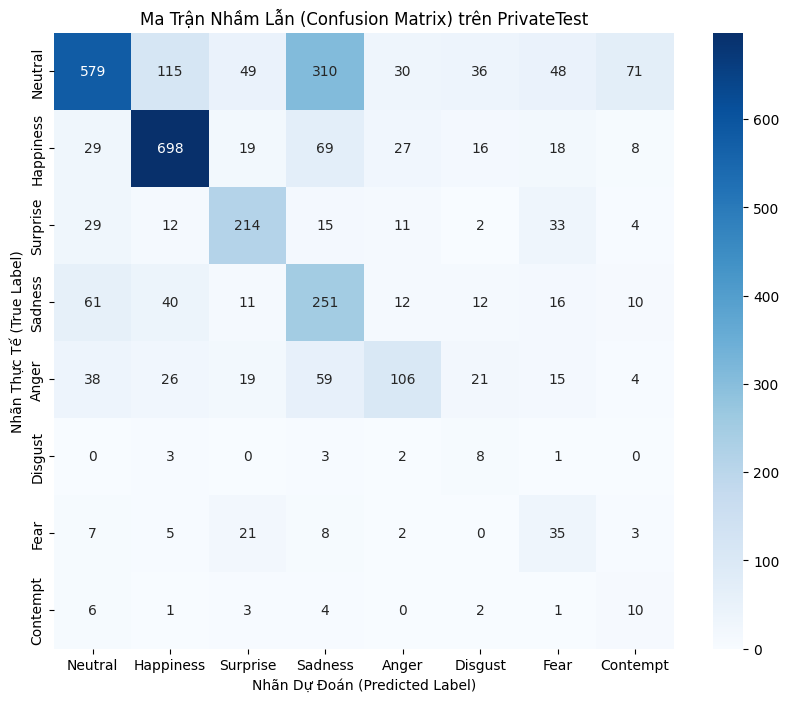

In [10]:
print("BẮT ĐẦU GIAI ĐOẠN 2: FINE-TUNING VỚI COSINE ANNEALING...")

# Đảm bảo biến best_val_acc tồn tại từ Giai đoạn 1 (tránh lỗi NameError)
if 'best_val_acc' not in globals():
    best_val_acc = 0.0

# 1. Nạp lại trọng số đỉnh cao nhất từ Giai đoạn 1
model.load_state_dict(torch.load('best_model.pth', weights_only=True))

# 2. Hạ tốc độ học xuống cực nhỏ (1e-4) và dùng Cosine Annealing
optimizer_ft = optim.SGD(model.parameters(), lr=1e-4, momentum=0.9, weight_decay=1e-4, nesterov=True)
scheduler_ft = optim.lr_scheduler.CosineAnnealingLR(optimizer_ft, T_max=20) # Chạy thêm 20 epochs

ft_epochs = 20
for epoch in range(ft_epochs):
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer_ft.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_ft.step()
        
    # Validation
    model.eval()
    val_correct = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            preds = torch.argmax(model(images), dim=1)
            val_correct += (preds == labels).sum().item()
            
    epoch_val_acc = val_correct / len(val_loader.dataset)
    scheduler_ft.step()
    
    # Nếu lập kỷ lục mới trong lúc fine-tuning thì ghi đè file
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save(model.state_dict(), 'best_model.pth')
        print(f"FT Epoch [{epoch+1}/{ft_epochs}] | Val Acc: {epoch_val_acc*100:.2f}% -> Lưu best_model.pth mới!")
    else:
        print(f"FT Epoch [{epoch+1}/{ft_epochs}] | Val Acc: {epoch_val_acc*100:.2f}%")

print("\n--- HOÀN TẤT HUẤN LUYỆN ---")

# ==========================================
# PHẦN ĐÁNH GIÁ (SỬA LẠI EMOTION DICT 8 LỚP)
# ==========================================
print("\nBẮT ĐẦU ĐÁNH GIÁ TRÊN TẬP TEST...")

# Nạp lại model tốt nhất sau cả 2 giai đoạn
model.load_state_dict(torch.load('best_model.pth', weights_only=True))
model.eval()

# TỪ ĐIỂN 8 LỚP CHUẨN CỦA FER+ (Đã sửa lỗi sai tên nhãn và thiếu Contempt)
emotion_dict = {
    0: 'Neutral', 
    1: 'Happiness', 
    2: 'Surprise', 
    3: 'Sadness', 
    4: 'Anger', 
    5: 'Disgust', 
    6: 'Fear', 
    7: 'Contempt'
}

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)
        
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

# In báo cáo phân loại và vẽ Confusion Matrix (từ eval_utils.py)
evaluate_private_test(y_true, y_pred, emotion_dict)

BẮT ĐẦU GIAI ĐOẠN 3: KIỂM ĐỊNH TRÊN TẬP PRIVATETEST BẰNG TEN-CROP...
=== BÁO CÁO KIỂM ĐỊNH (CLASSIFICATION REPORT) ===
              precision    recall  f1-score   support

     Neutral       0.73      0.52      0.61      1238
   Happiness       0.79      0.79      0.79       884
    Surprise       0.72      0.63      0.67       320
     Sadness       0.29      0.71      0.41       413
       Anger       0.72      0.11      0.19       288
     Disgust       0.07      0.29      0.11        17
        Fear       0.33      0.19      0.24        81
    Contempt       0.09      0.22      0.13        27

    accuracy                           0.58      3268
   macro avg       0.47      0.43      0.39      3268
weighted avg       0.67      0.58      0.59      3268



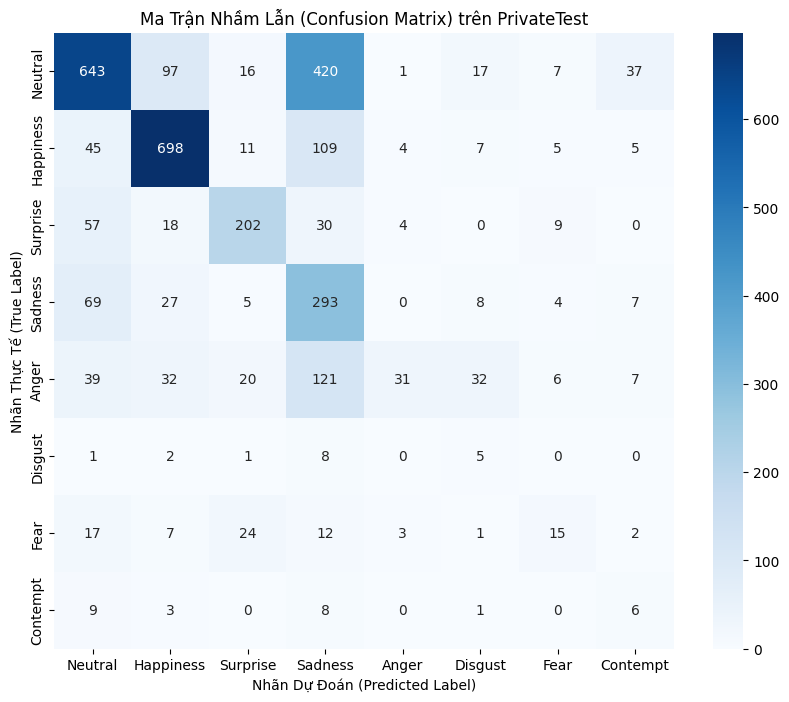

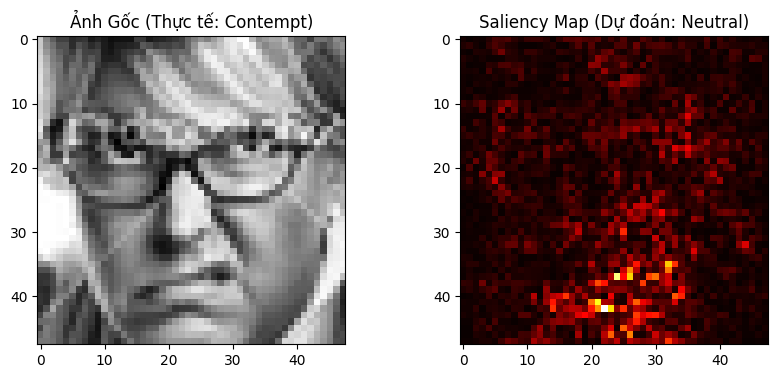

In [13]:
print("BẮT ĐẦU GIAI ĐOẠN 3: KIỂM ĐỊNH TRÊN TẬP PRIVATETEST BẰNG TEN-CROP...")

# 1. Nạp file trọng số cuối cùng (Sửa thành 'best_model_custom.pth' nếu bạn đã đổi tên file ở bước trước)
model.load_state_dict(torch.load('best_model.pth', weights_only=True))
model.eval()

y_true = []
y_pred = []

# 2. Chạy Ten-Crop Averaging (Lưu ý: Mất nhiều thời gian hơn một chút vì 1 ảnh thành 10 ảnh)
for images, labels in test_loader:
    for i in range(images.size(0)):
        img_tensor = images[i]
        true_label = labels[i].item()
        
        # Gọi hàm từ eval_utils.py
        pred_label, _ = ten_crop_inference(model, img_tensor)
        
        y_true.append(true_label)
        y_pred.append(pred_label)

# 3. Xuất Báo cáo và Ma trận nhầm lẫn (Đã cập nhật chuẩn 8 lớp của FER+)
emotion_dict = {
    0: 'Neutral', 
    1: 'Happiness', 
    2: 'Surprise', 
    3: 'Sadness', 
    4: 'Anger', 
    5: 'Disgust', 
    6: 'Fear', 
    7: 'Contempt'
}
evaluate_private_test(y_true, y_pred, emotion_dict)

# 4. Trực quan hóa Saliency Map cho 1 ảnh Test bất kỳ
sample_img = test_dataset[0][0] # Lấy ảnh đầu tiên của tập Test
sample_label = test_dataset[0][1].item()

saliency, pred_class = generate_saliency_map(model, sample_img)

# Vẽ đồ thị Saliency
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(sample_img.squeeze().numpy(), cmap='gray')
plt.title(f"Ảnh Gốc (Thực tế: {emotion_dict[sample_label]})")

plt.subplot(1, 2, 2)
plt.imshow(saliency, cmap='hot')
plt.title(f"Saliency Map (Dự đoán: {emotion_dict[pred_class]})")
plt.show()

In [14]:
import shutil

# Nén toàn bộ file trong thư mục đầu ra thành ketqua_custom.zip
shutil.make_archive('/kaggle/working/ketqua_custom', 'zip', '/kaggle/working')
print("Đã nén xong! Tải file ketqua_custom.zip ở cột Output bên phải.")

Đã nén xong! Tải file ketqua_custom.zip ở cột Output bên phải.
